# SQL Playground
DuckDB + Jupyter. Everything you create is stored in `work/playground.duckdb` and survives restarts.

1. Define a schema with SQL → draw the ER diagram
2. Or draw the ER diagram as text (Mermaid) → get the schema generated
3. Play with queries

In [3]:
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
import erplay
con = erplay.connect("flughafen")
%sql con

## 1. Schema with SQL
Re-running this cell is safe: it starts with a clean database.

In [4]:
erplay.reset(con)

In [5]:
%%sql
DROP TABLE if EXISTS FlugzeugAirport;

DROP TABLE if EXISTS Niederlassung;

DROP TABLE if EXISTS Flugzeug;

DROP TABLE if EXISTS Airport;

DROP TABLE if EXISTS Flugzeughersteller;

CREATE TABLE
  Flugzeughersteller (id INTEGER PRIMARY KEY, name VARCHAR,);

CREATE TABLE
  Flugzeug (
    id INTEGER PRIMARY KEY,
    type VARCHAR,
    flugzeughersteller_id INTEGER REFERENCES flugzeughersteller (id),
  );

CREATE TABLE
  Airport (id INTEGER PRIMARY KEY, name VARCHAR);

CREATE TABLE
  FlugzeugAirport (
    flugzeug_id INTEGER REFERENCES flugzeug (id),
    airport_id INTEGER REFERENCES airport (id),
    PRIMARY KEY (flugzeug_id, airport_id)
  );

CREATE TABLE
  Niederlassung (
    id INTEGER PRIMARY KEY,
    airport_id INTEGER REFERENCES airport (id),
    flugzeughersteller_id INTEGER REFERENCES flugzeughersteller (id)
  );

,Count


In [6]:
%%sql
INSERT INTO
  flugzeughersteller
VALUES
  (1, 'Boing'),
  (2, 'Airbus'),
  (3, 'McDougles');

INSERT INTO
  flugzeug
VALUES
  (1, '747', 1),
  (2, 'A380', 2),
  (3, 'A320', 2);

INSERT INTO
  airport
VALUES
  (1, 'Frankfurt'),
  (2, 'Hamburg');

INSERT INTO
  niederlassung
VALUES
  (1, 1, 2),
  (2, 2, 3),
  (3, 1, 1),
  (4, 2, 2),
  (5, 1, 1);

,Count


## 2. ER diagram of the current database

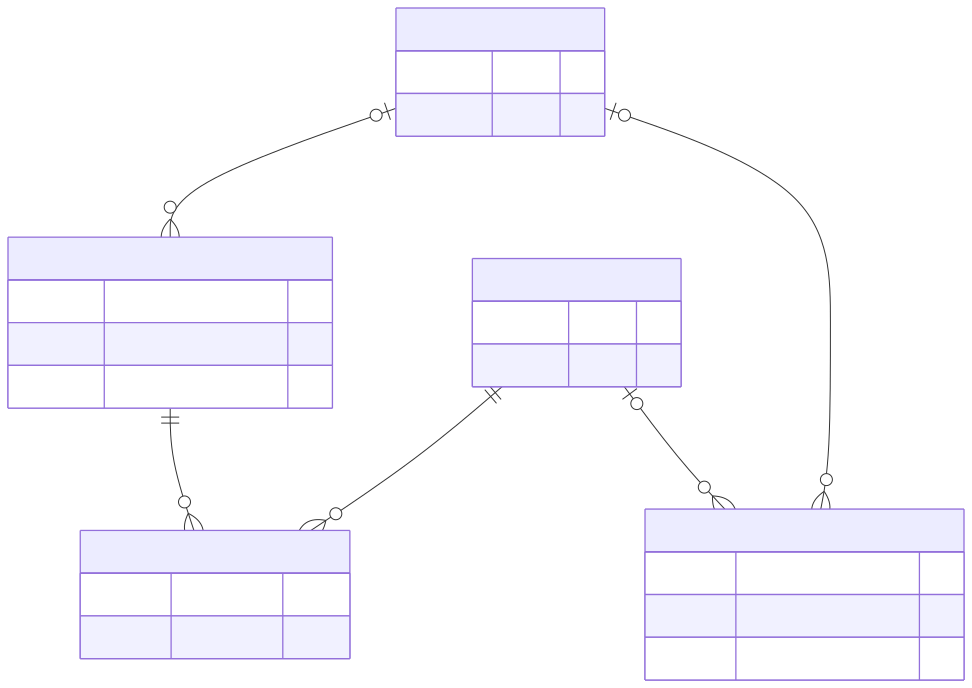

In [7]:
erplay.er_diagram(con)

The same schema as editable Mermaid text (paste it into any Mermaid renderer, e.g. GitHub markdown or mermaid.live):

In [8]:
print(erplay.schema_to_mermaid(con))

erDiagram
    Flugzeughersteller |o--o{ Flugzeug : flugzeughersteller_id
    Flugzeug ||--o{ FlugzeugAirport : flugzeug_id
    Airport ||--o{ FlugzeugAirport : airport_id
    Airport |o--o{ Niederlassung : airport_id
    Flugzeughersteller |o--o{ Niederlassung : flugzeughersteller_id
    Airport {
        INTEGER id PK
        VARCHAR name
    }
    Flugzeug {
        INTEGER id PK
        VARCHAR type
        INTEGER flugzeughersteller_id FK
    }
    FlugzeugAirport {
        INTEGER flugzeug_id PK, FK
        INTEGER airport_id PK, FK
    }
    Flugzeughersteller {
        INTEGER id PK
        VARCHAR name
    }
    Niederlassung {
        INTEGER id PK
        INTEGER airport_id FK
        INTEGER flugzeughersteller_id FK
    }


## 3. Queries

In [9]:
%%sql
SELECT
  fl.id AS Flugzeugid,
  fl.type AS Flugzeugtype,
  a.name
FROM
  airport a
  JOIN niederlassung n ON a.id = n.airport_id
  JOIN flugzeughersteller fh ON n.flugzeughersteller_id = fh.id
  JOIN flugzeug fl ON fh.id = fl.flugzeughersteller_id

,Flugzeugid,Flugzeugtype,name
0,1,747,Frankfurt
1,2,A380,Hamburg
2,3,A320,Hamburg
3,1,747,Frankfurt
4,2,A380,Frankfurt
5,3,A320,Frankfurt


In [10]:
%%sql
SELECT
  COUNT(*),
  a.name
FROM
  airport a
  JOIN niederlassung n ON a.id = n.airport_id
GROUP BY
  a.name

,count_star(),name
0,3,Frankfurt
1,2,Hamburg


Your turn: write your own queries below.

In [11]:
%%sql
SELECT
  COUNT(*),
  a.name,
  fh.name
FROM
  airport a
  JOIN niederlassung n ON a.id = n.airport_id
  JOIN flugzeughersteller fh ON n.flugzeughersteller_id = fh.id
GROUP BY
  a.name,
  fh.name

,count_star(),name,name_1
0,2,Frankfurt,Boing
1,1,Hamburg,Airbus
2,1,Frankfurt,Airbus
3,1,Hamburg,McDougles


## 4. ER diagram → schema
Describe entities and relationships as a Mermaid `erDiagram`; the tables and foreign keys are generated.

* `A ||--o{ B` = one A has zero or many B (B gets a foreign key to A)
* `|o` / `o|` = the parent is optional (nullable foreign key)
* `}o--o{` = many-to-many (a junction table is created)
* Mark keys with `PK`, `FK`, `UK` after the column name

This wipes the database first.

CREATE TABLE "AUTHOR" (
  "id" INTEGER PRIMARY KEY,
  "name" VARCHAR
);

CREATE TABLE "MEMBER" (
  "id" INTEGER PRIMARY KEY,
  "name" VARCHAR,
  "email" VARCHAR UNIQUE
);

CREATE TABLE "BOOK" (
  "id" INTEGER PRIMARY KEY,
  "title" VARCHAR,
  "year" INTEGER,
  "author_id" INTEGER NOT NULL,
  FOREIGN KEY ("author_id") REFERENCES "AUTHOR" ("id")
);

CREATE TABLE "LOAN" (
  "id" INTEGER PRIMARY KEY,
  "loaned_on" DATE,
  "member_id" INTEGER NOT NULL,
  "book_id" INTEGER NOT NULL,
  FOREIGN KEY ("member_id") REFERENCES "MEMBER" ("id"),
  FOREIGN KEY ("book_id") REFERENCES "BOOK" ("id")
);


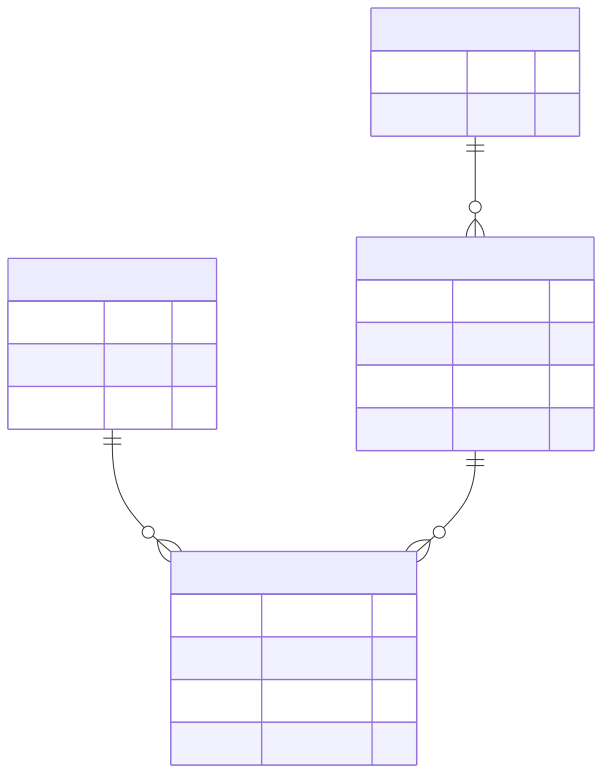

In [12]:
erplay.reset(con)
diagram = """
erDiagram
    AUTHOR ||--o{ BOOK : writes
    MEMBER ||--o{ LOAN : makes
    BOOK   ||--o{ LOAN : "is lent in"
    AUTHOR {
        int id PK
        string name
    }
    BOOK {
        int id PK
        string title
        int year
    }
    MEMBER {
        int id PK
        string name
        string email UK
    }
    LOAN {
        int id PK
        date loaned_on
    }
"""
erplay.apply_mermaid(con, diagram)